# Main tutorial: one FE Walter decision, end to end

This walkthrough follows one bounded three-day case from input and YAML through
the decision method, current checks, saved execution, verification, and bound
audit/trace evidence. It compares a deterministic Hanasaki-based rule with two
already-completed local Ollama runs. No model is called while this notebook runs.

![HydroOpsLM coupling concept](../docs/figures/hydrocnhs-coupling-framework-en.png)

The decision path is **info → system/user prompt → saved rule or model output →
current action-contract recheck → implemented release → next info**. Historical
events remain historical; a current recheck never becomes a claimed past event.

## Setup

The notebook reads repository snapshots only. The builder blocks network access
and records displayed tables and figures as rich notebook outputs.

In [1]:
from pathlib import Path
import html, json, re, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/hydrocnhs").is_dir())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from llm_reservoir_agent.workflow import load_settings
from llm_reservoir_agent.verification import verify_run
from tutorials.inspect_decision_flow import load_decision_flow

class ReadableText:
    """Render preserved text as a readable notebook block."""
    def __init__(self, title, text):
        self.title, self.text = title, text
    def _repr_markdown_(self):
        fence = "`" * max(4, 1 + max((len(run) for run in re.findall(r"`+", self.text)), default=0))
        return f"#### {self.title}\n\n{fence}text\n{self.text}\n{fence}"
    def _repr_html_(self):
        return f'<h4>{html.escape(self.title)}</h4><pre class="prompt-text">{html.escape(self.text)}</pre>'

def jsonl(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines()]

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.figsize": (9, 4.8), "axes.grid": True, "figure.dpi": 120})

## 1. Input: the same inflow, physical state, losses, and routing

The inflow is simulated, already aggregated and routed to the reservoir node.
Initial storage **2,457,848.279729185 m³ (1,992.61 acre-ft)** is an integration
assumption. Losses are zero and `UH=[1.0]` is identity routing, not a calibrated
downstream reach.

![FE Walter study map](../docs/figures/fe-walter-study-map.png)

In [2]:
inflow = pd.read_csv(ROOT / "cases/fe_walter_reference/inflows.csv")
inflow = inflow.loc[inflow["node"] == "FEW_INFLOW", ["date", "local_inflow_cms"]]
inflow = inflow.rename(columns={"local_inflow_cms": "inflow (m³/s)"})
case = json.loads((ROOT / "cases/fe_walter_ollama_demo/case.json").read_text(encoding="utf-8"))
physical = case["network"]["reservoirs"]["FEWalter"]["physical"]
assumptions = pd.DataFrame([
    ("initial storage", physical["initial_storage_m3"], "m³"),
    ("minimum release", physical["minimum_release_cms"], "m³/s"),
    ("maximum release", physical["maximum_release_cms"], "m³/s"),
    ("evaporation / seepage", 0.0, "m³/day"),
    ("downstream unit hydrograph", str(case["network"]["connections"][0]["unit_hydrograph"]), "dimensionless"),
], columns=["item", "value", "unit"])
display(inflow)
display(assumptions)

,date,inflow (m³/s)
0,2016-01-01,32.125319
2,2016-01-02,22.353047
4,2016-01-03,14.193931


,item,value,unit
0,initial storage,2457848.279729,m³
1,minimum release,1.415842,m³/s
2,maximum release,283.16847,m³/s
3,evaporation / seepage,0.0,m³/day
4,downstream unit hydrograph,[1.0],dimensionless


## 2. YAML and local check

The rule snapshot uses the same Ollama-case file as the LLM snapshots and frozen
1996–2015 Hanasaki statistics. `load_settings` performs the same local planning
check as the CLI `check` command and makes no provider request.

In [3]:
configs = {
    "Rule": "tutorials/config/fe_walter_tutorial_benchmark.yaml",
    "Zero-shot": "examples/fe_walter/zero_shot/experiment.ollama.yaml",
    "DKP": "examples/fe_walter/dkp/experiment.ollama.yaml",
}
plans = []
for method, relative in configs.items():
    report = load_settings(ROOT / relative).report
    plans.append({
        "method": method,
        "dates": f"{report['start_date']} to {report['end_date']}",
        "days": report["days"],
        "planned model calls": report["planned_llm_calls"],
        "max calls": report["max_calls"],
        "configuration": relative,
    })
display(pd.DataFrame(plans))

,method,dates,days,planned model calls,max calls,configuration
0,Rule,2016-01-01 to 2016-01-03,3,0,0,tutorials/config/fe_walter_tutorial_benchmark.yaml
1,Zero-shot,2016-01-01 to 2016-01-03,3,3,3,examples/fe_walter/zero_shot/experiment.ollama.yaml
2,DKP,2016-01-01 to 2016-01-03,3,3,3,examples/fe_walter/dkp/experiment.ollama.yaml


## 3. Rule or prompt: inspect preserved decision evidence

The two LLM paths below read real saved Ollama evidence (`gemma3:4b`, temperature
0.7, three completed calls per method, no retries). The complete first-day
system and user prompts are displayed as readable text. DKP adds conditionally
retrieved knowledge; zero-shot does not. Raw records remain linked below.

[Zero-shot raw traces](../examples/fe_walter/reference_outputs/ollama_three_day/zero_shot/raw/) ·
[DKP raw traces](../examples/fe_walter/reference_outputs/ollama_three_day/dkp/raw/)

In [4]:
saved = ROOT / "examples/fe_walter/reference_outputs/ollama_three_day"
zero_flow = load_decision_flow(saved / "zero_shot", timestep=0)
dkp_flow = load_decision_flow(saved / "dkp", timestep=0)
info = zero_flow["info"]
display(pd.DataFrame([{
    "date": zero_flow["prompt_variables"]["date"],
    "inflow (m³/s)": info["inflow_cms"],
    "starting storage (m³)": info["state"]["storage_m3"],
    "method": "Zero-shot saved Ollama",
}]))
display(ReadableText("Complete saved system prompt", zero_flow["system_prompt"]))
display(ReadableText("Complete saved zero-shot user prompt", zero_flow["prompt"]))
display(ReadableText("Complete saved DKP system prompt", dkp_flow["system_prompt"]))
display(ReadableText("Complete saved DKP user prompt with retrieved knowledge", dkp_flow["prompt"]))

,date,inflow (m³/s),starting storage (m³),method
0,2016-01-01,32.125319,2.457848e+06,Zero-shot saved Ollama


#### Complete saved system prompt

````text
You are the operator of a reservoir, making one release decision per day.

Reservoir information (public sources):
- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania
- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania
- Purpose: flood control, water storage, recreation
- Opened: 1961; operated by the U.S. Army Corps of Engineers
- Type: earth-fill embankment with rock shell, impounding the Lehigh River
- Dam height (foundation): 234 ft; length: 3,000 ft
- Spillway type: concrete
- Catchment area: 289 square miles
- Total capacity (publicly reported): 110,700 acre-feet
- Operation target: Your goal is to keep the water level at or near the designated normal pool elevation: 1300.0 ft N.G.V.D. in the winter (November through April) and 1370.0 ft N.G.V.D. in the summer (May through October).

Each day you will receive the current date, mean inflow,
water level at the beginning of the interval, and the previous one or two
simulated release decisions.
Flows are also stated as volumes in cubic feet over their interval, the
unit of the water balance. Decide the interval's mean release
in cfs, consistent with the reservoir's purpose. You have no operating
manual; use general reservoir-operation principles.

Physical water balance (not an operating rule):
- storage_change_cubic_feet = (inflow_cfs - release_cfs) * 86,400 * interval_days.
- A release below inflow increases storage; a release equal to inflow
  leaves storage approximately unchanged; a release above inflow decreases
  storage. Passing inflow cannot refill a reservoir below its target.

Constraints you must respect:
- Do not plan to release more water than is available (storage + inflow).
- Avoid letting storage exceed capacity (uncontrolled spill).
- Avoid abrupt interval-to-interval release changes unless conditions require them.

Respond only with JSON, with the fields in this order:
  applicable_target_ft (the operation-target water level for this interval),
  pool_position (below_target | at_target | above_target),
  intended_storage_direction (increase | hold | decrease),
  release_relation_to_inflow (below_inflow | equal_to_inflow | above_inflow),
  reasoning (1-2 sentences), release_cfs (number).
Decide the first four, then write the reasoning, then choose release_cfs.
Make release_cfs consistent with the four fields and with your reasoning.
````

#### Complete saved zero-shot user prompt

````text
Date: 2016-01-01 (January, day 1 of the year)
1. Today's inflow: 1,134.5 cfs (= 98,020,360 cubic feet (= 2,250 acre-feet) over 1 days)
2. Water level at beginning of interval: 1300.00 ft NGVD29
3. Previous simulated release decisions (and what was actually released):
   None (first simulated step).
4. Number of days in this decision interval: 1

Decide the mean release for this interval (cfs).
````

#### Complete saved DKP system prompt

````text
You are the water control manager operating F.E. Walter Dam on the Lehigh River, Pennsylvania,
making one release decision per day.

Reservoir information (public sources):
- Name: F.E. Walter Dam on the Lehigh River, Pennsylvania
- Location: Bear Creek Township, Luzerne County and Kidder Township, Carbon County, Pennsylvania
- Purpose: flood control, water storage, recreation
- Opened: 1961; operated by the U.S. Army Corps of Engineers
- Type: earth-fill embankment with rock shell, impounding the Lehigh River
- Dam height (foundation): 234 ft; length: 3,000 ft
- Spillway type: concrete
- Catchment area: 289 square miles
- Total capacity (publicly reported): 110,700 acre-feet
- Operation target: Your goal is to keep the water level at or near the designated normal pool elevation: 1300.0 ft N.G.V.D. in the winter (November through April) and 1370.0 ft N.G.V.D. in the summer (May through October).

From the reservoir's water control manual:
- Storage at spillway crest (el. 1450.0 ft): 109,878 acre-feet
- Maximum allowable release: 10,000 cfs
- Minimum required release: 50 cfs

Your operating knowledge comes from the reservoir's Decision
Knowledge Package (DKP), extracted from the project's official
water control manual. Each day, the sections of the DKP most
relevant to the current conditions are retrieved and provided to
you together with the system state. Base your decision on those
retrieved DKP excerpts: apply their operating zones, decision
rules, release constraints, rating tables, and seasonal guidance.
This model represents the reservoir only: storage, inflow and release.
Apply the storage, inflow, seasonal and release-limit rules.
Do not invent an observation or rule.

How to apply the DKP in this simulation:
- Storage-to-elevation conversion is physical preprocessing and the current
  pool elevation may be supplied. Apply the shared operation target stated
  in the reservoir information; do not derive a different target from the DKP.
- Compare the current pool with that target yourself; no precomputed
  above-target or below-target interpretation is supplied.
- Gate-position rate limits are not discharge-rate limits. Do not convert
  them to cfs per hour without the required gate-rating information.
- Exhibit D's numerical recreation calendar is explicitly specific to 2014.
  In every other year, apply only the structural recreation constraints
  stated by the DKP and identify the annual calendar as unavailable; do not
  transfer the 2014 weekday, weekend, event-date, or numeric release schedule.
- No recommended release, target-tracking controller output, or precomputed
  above/below-target label is supplied. Select the release independently
  from the retrieved DKP rules and the raw state values.
- If the DKP does not provide a unique numeric release for the available
  inputs, do not invent an official formula. Choose the most defensible
  action allowed by the retrieved rules and explain it in the reasoning.
- No external reduced-domain release rule is supplied in this run.
- Use store_toward_target or draw_toward_target only when the selected
  release actually changes storage in that direction. Use pass_inflow only
  when the selected release is approximately equal to inflow.
- During seasonal refill, report store_toward_target; during seasonal
  drawdown, report draw_toward_target. Reserve recreation_plan for an
  applicable dated recreation-release instruction whose calendar is known.

Physical water balance (not an operating rule):
- storage_change_cubic_feet = (inflow_cfs - release_cfs) * 86,400 * interval_days.
- A release below inflow increases storage; a release equal to inflow
  leaves storage approximately unchanged; a release above inflow decreases
  storage. Passing inflow cannot refill a reservoir below its target.

Reduced-model hard constraints on your answer:
- Release between 50 and 10,000 cfs.
- Do not plan to release more water than is available (s

#### Complete saved DKP user prompt with retrieved knowledge

````text
Date: 2016-01-01 (January, day 1 of the year)
1. Today's inflow: 1,134.5 cfs (= 98,020,360 cubic feet (= 2,250 acre-feet) over 1 days)
2. Water level at beginning of interval: 1300.00 ft NGVD29
3. Previous simulated release decisions (and what was actually released):
   None (first simulated step).
4. Number of days in this decision interval: 1
5. Release limits for this interval (water control manual): 50-10,000 cfs (= 4,320,000-864,000,000 cubic feet over 1 days)

Retrieved DKP sections relevant to current conditions:

--- DKP excerpt 1: R-RELEASE (composite per-timestep decision; WCM Table 7-1 Parts A and B; §7-01, §7-03, §7-05) ---
```pseudo
plan = R-PLAN(pool_elevation, stages, season)

active_min = R-MINFC       if plan in {C, D} or impounding_for_flood_emergency   # 100 cfs
           | R-MINDROUGHT  if drbc_drought_declared                              #  43 cfs
           | R-MINNORM                                                           #  50 cfs

CASE plan OF
  A:  release = inflow_cfs, holding pool at or near target_pool_ft;
        obligations = Minimum Release Schedule + Water Quality Release Schedule (R-TEMP)

  B:  release_combined = MaxReleaseSchedule_Rising(stages)      # §2.4.5 — MOST RESTRICTIVE gage governs
        release_walter  = R-BALANCE(release_combined, pct_fc_storage_used,
                                    beltzville_state.pct_fc_storage_used)
        summer: defer to Exhibit D Recreation Plan (NOT SUPPLIED)
        apply R-FILLING whenever pool exceeds any previously attained elevation

  C:  release = active_min                                       # store all inflow at BOTH projects
        on stages_trend == falling_after_peak, switch to MaxReleaseSchedule_Falling (§2.4.5)

  D:  release = pass inflow (hourly or finer), gates incrementally to full open;
        once outlet capacity exceeded, HOLD full open until pool < EL_SPILLWAY;
        then outflow = inflow until MaxReleaseSchedule_Rising (Plan B) can be resumed

release = clip(release, lower = active_min,
                        upper = min( Q_CHANNEL_CAP,            # conditional — see R-ATSITE
                                     outlet_capacity(pool_elevation),
                                     R-DOWNSTREAM limit ) )

subject to R-ROC (gate-position limits, NOT a discharge-rate limit)

IF pool_elevation > EL_SPILLWAY:
    total_outflow = release + spillway_discharge(pool_elevation)   # uncontrolled, §2.4.3
```

--- DKP excerpt 2: R-MINNORM, R-MINFC, R-MINDROUGHT (Minimum Release Schedule; WCM Table 7-1 Part B; §7-01, §7-05,c,3, §8-04) ---
```pseudo
Flows maintained at the reservoir OUTFLOW gaging station (White Haven for Walter):

   Regulation purpose                     Walter (cfs)   Beltzville (cfs)
   1. Flood control regulation (storing)      100              35     -> R-MINFC
   2. Normal regulation                        50              35     -> R-MINNORM
   3. Drought warning and drought               43              15     -> R-MINDROUGHT

Precedence: R-MINFC applies whenever storing under Plans C/D; R-MINDROUGHT relaxes
R-MINNORM under a declared DRBC drought warning or emergency; R-MINNORM otherwise.
The 50 cfs is a Commonwealth of Pennsylvania Fish Commission requirement set to protect
downstream brook trout habitat (Table 7-1 Part B).
```

--- DKP excerpt 3: R-ATSITE (maximum release; WCM §4-09, §7-02a, §7-05,c,1, Table 7-2 notes 1–2) ---
```pseudo
release ≤ 10,000 cfs  "during non-spillway flow conditions ... should not be exceeded IF POSSIBLE"
   equivalently: stage_WhiteHaven ≤ 8.4 ft (Table 7-1 Part B note 5)
release ≤ outlet_capacity(pool_elevation)   [≈17,000 cfs at EL_SPILLWAY]

EXCEPTION (Table 7-2 note 1): during FALLING stages after a peak, releases in excess of
10,000 cfs MAY be considered, provided the release — combined with Beltzville's — does not
cause any key Lehigh station to exceed max(event_peak_stage, flood stage), whicheve

In [5]:
rule_decisions = jsonl(ROOT / "examples/fe_walter/reference_outputs/rule_three_day/decisions.jsonl")
rule_output = pd.DataFrame([{
    "date": row["timestamp"],
    "rule output: requested release (m³/s)": row["action"]["release_cms"],
    "decision ID": row["decision_id"],
} for row in rule_decisions])
llm_outputs = pd.DataFrame([
    {"method": "Zero-shot",
     "normalized requested release (m³/s)": zero_flow["proposal"]["release_cms"]},
    {"method": "DKP",
     "normalized requested release (m³/s)": dkp_flow["proposal"]["release_cms"]},
])
display(rule_output)
display(llm_outputs)
for method, slug, flow in (("Zero-shot", "zero_shot", zero_flow), ("DKP", "dkp", dkp_flow)):
    trace = json.loads((saved / slug / flow["trace_files"]["policy"]).read_text(encoding="utf-8"))["backend_trace"]
    display(ReadableText(f"Complete saved {method} model reply",
                         trace["provider_reply"]["message"]["content"]))
    display(ReadableText(f"{method} common action (m³/s)",
                         json.dumps(flow["proposal"], indent=2)))

,date,rule output: requested release (m³/s),decision ID
0,2016-01-01,25.098588,a55e8402dabaa06d6127816db201078ccaff0234147efb071c505797a92cdd3a
1,2016-01-02,17.490024,f0cd7e1920b1d0f0b63f3376df7332709961af0b5f00287d0a65cfc1c2dd6723
2,2016-01-03,11.137442,212d1114bd88811e825758c5d8a385d6026f450b586e4b809acf609fbb804f36


,method,normalized requested release (m³/s)
0,Zero-shot,32.125463
1,DKP,1.415842


#### Complete saved Zero-shot model reply

````text
{"applicable_target_ft": 1300.00, "pool_position": "at_target", "intended_storage_direction": "hold", "release_relation_to_inflow": "equal_to_inflow", "reasoning": "Given the target water level of 1300.0 ft and the inflow of 1134.5 cfs, a release equal to inflow is appropriate to maintain the target. This will hold the current storage level.", "release_cfs": 1134.5}
````

#### Zero-shot common action (m³/s)

````text
{
  "schema_version": "reservoir-action.v1",
  "release_cms": 32.1254629215
}
````

#### Complete saved DKP model reply

````text
{"applicable_target_ft": 1300.00, "pool_position": "at_target", "intended_storage_direction": "hold", "release_relation_to_inflow": "equal_to_inflow", "operating_mode": "minimum_release", "rules_applied": ["R-RELEASE", "R-MINNORM", "R-ZONE"], "reasoning": "Today is January 1st, and the operation target is 1300.0 ft. The DKP excerpt 2 states that R-MINNORM is applied unless a drought warning is declared. Since there is no drought warning declared, we apply R-MINNORM which specifies a minimum release of 50 cfs. The DKP excerpt 4 dictates that the target pool is 1300.0 ft and we are holding the pool at this level, so the release is equal to the inflow. The inflow is 1134.5 cfs. Therefore, the release should be 50 cfs plus 1134.5 cfs = 1139.5 cfs. However, the DKP excerpt 3 states that the maximum release is 10000 cfs. Since 1139.5 cfs < 10000 cfs, we will apply R-MINNORM. The release will be 50 cfs.", "release_cfs": 50}
````

#### DKP common action (m³/s)

````text
{
  "schema_version": "reservoir-action.v1",
  "release_cms": 1.41584235
}
````

## 4. Run and verify: default to saved snapshots

The default tutorial does **not** run a simulation or model. It verifies three
saved snapshots and reads their committed trajectories. The deterministic rule
snapshot has zero network calls. Both LLM snapshots retain their original audit
outcomes: zero-shot has **2 PASS / 1 FAIL**, DKP has **3 FAIL**, and
`operating_strategy_accepted` is `null` for all three methods.

In [6]:
outputs = {
    "Rule": ROOT / "examples/fe_walter/reference_outputs/rule_three_day",
    "Zero-shot": saved / "zero_shot",
    "DKP": saved / "dkp",
}
verification_rows = []
for method, output in outputs.items():
    result = verify_run(output, require_offline=(method == "Rule"))
    verification_rows.append({
        "method": method,
        "verification": result["status"],
        "days": result["days"],
        "audit counts": str(result["audit_counts"]),
        "historical model calls": result["observed_network_calls"],
        "max system residual (m³)": result["max_system_balance_residual_m3"],
        "operating strategy accepted": result["operating_strategy_accepted"],
    })
display(pd.DataFrame(verification_rows))

,method,verification,days,audit counts,historical model calls,max system residual (m³),operating strategy accepted
0,Rule,PASS,3,{'PASS': 3},0,2.328306e-10,None
1,Zero-shot,PASS,3,"{'PASS': 2, 'FAIL': 1}",3,0.000000e+00,None
2,DKP,PASS,3,{'FAIL': 3},3,8.731149e-10,None


In [7]:
frames = []
for method, output in outputs.items():
    trajectory = pd.read_csv(output / "reservoir_trajectory.csv")
    audits = jsonl(output / "audit.jsonl")
    trajectory["date"] = trajectory["date"].str[:10]
    trajectory["method"] = method
    trajectory["audit"] = [row["status"] for row in audits]
    frames.append(trajectory[["method", "date", "inflow_cms", "target_release_cms",
                              "controlled_release_cms", "total_outflow_cms", "spill_cms", "storage_end_m3", "audit"]])
comparison = pd.concat(frames, ignore_index=True).rename(columns={
    "inflow_cms": "inflow (m³/s)",
    "target_release_cms": "requested release (m³/s)",
    "controlled_release_cms": "implemented release (m³/s)",
    "total_outflow_cms": "total outflow (m³/s)",
    "spill_cms": "spill (m³/s)",
    "storage_end_m3": "end storage (m³)",
})
display(comparison)

,method,date,inflow (m³/s),requested release (m³/s),implemented release (m³/s),total outflow (m³/s),spill (m³/s),end storage (m³),audit
0,Rule,2016-01-01,32.125319,25.098588,25.098588,25.098588,0.0,3.064958e+06,PASS
1,Rule,2016-01-02,22.353047,17.490024,17.490024,17.490024,0.0,3.485123e+06,PASS
2,Rule,2016-01-03,14.193931,11.137442,11.137442,11.137442,0.0,3.749204e+06,PASS
3,Zero-shot,2016-01-01,32.125319,32.125463,32.125463,32.125463,0.0,2.457836e+06,PASS
4,Zero-shot,2016-01-02,22.353047,22.353319,22.353319,22.353319,0.0,2.457812e+06,PASS
5,Zero-shot,2016-01-03,14.193931,22.353319,22.353319,22.353319,0.0,1.752841e+06,FAIL
6,DKP,2016-01-01,32.125319,1.415842,1.415842,1.415842,0.0,5.111147e+06,FAIL
7,DKP,2016-01-02,22.353047,1.415842,1.415842,1.415842,0.0,6.920122e+06,FAIL
8,DKP,2016-01-03,14.193931,1.415842,1.415842,1.415842,0.0,8.024148e+06,FAIL


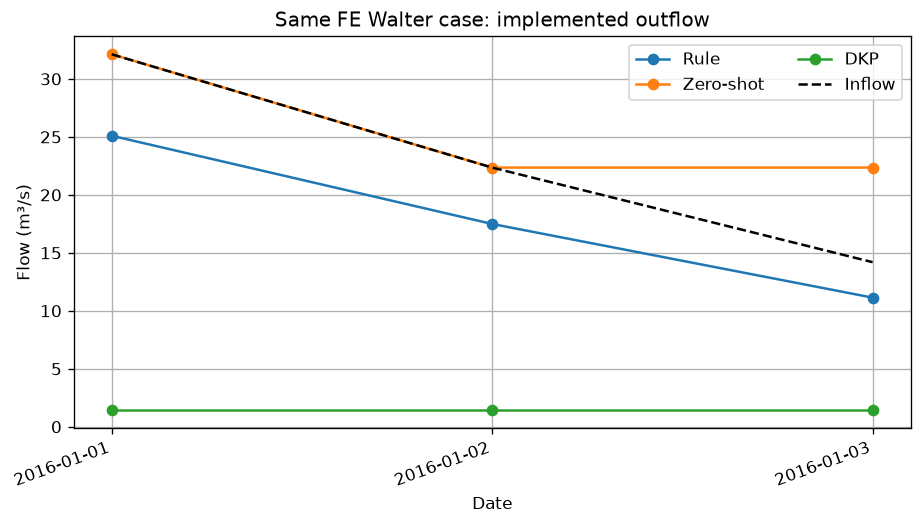

In [8]:
fig, ax = plt.subplots()
for method, group in comparison.groupby("method", sort=False):
    ax.plot(group["date"], group["total outflow (m³/s)"], marker="o", label=method)
ax.plot(inflow["date"], inflow["inflow (m³/s)"], color="black", linestyle="--", label="Inflow")
ax.set(title="Same FE Walter case: implemented outflow", ylabel="Flow (m³/s)", xlabel="Date")
ax.legend(ncol=2)
fig.autofmt_xdate(rotation=20)
export = ROOT / "tutorials/assets/fe_walter_three_method.png"
export.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(export, dpi=160, bbox_inches="tight", metadata={"Software": "HydroOpsLM tutorial"})
display(fig)

## 5. Audit and trace: preserved verdicts versus current revalidation

`load_decision_flow` binds each decision to its raw provider record, saved audit,
implemented physics, and next observation. `current_recheck` parses the saved
action against today’s common action contract. It is explicitly a **current
recheck**, not evidence that a historical checker event existed.

In [9]:
chains = []
for method, slug, flow in (("Zero-shot", "zero_shot", zero_flow), ("DKP", "dkp", dkp_flow)):
    stages = [
        ("info", flow["prompt_variables"]["date"], "historical saved observation"),
        ("provider completion", str(flow["provider_evidence"]["completion"]), "historical saved provider evidence"),
        ("requested release", flow["saved_requested_action"]["release_cms"], "historical saved action, m³/s"),
        ("response checks", flow["current_recheck"]["action_contract"], "current action-contract recheck"),
        ("operation audit", flow["saved_audit"]["status"], "historical saved verdict"),
        ("implemented total outflow", flow["saved_implemented_physics"]["total_outflow_cms"], "historical physics, m³/s"),
        ("next storage", flow["next_info"]["state"]["storage_m3"], "next historical info, m³"),
    ]
    chains.extend({"method": method, "stage": stage, "value": value, "evidence meaning": meaning}
                  for stage, value, meaning in stages)
    next_flow = load_decision_flow(saved / slug, timestep=1)
    display(ReadableText(f"{method}: implemented release history in the next prompt",
                         json.dumps(next_flow["saved_native_history"], indent=2, ensure_ascii=False)))
display(pd.DataFrame(chains))
display(pd.DataFrame([{"method": method, **flow["trace_files"]}
                      for method, flow in (("Zero-shot", zero_flow), ("DKP", dkp_flow))]))

#### Zero-shot: implemented release history in the next prompt

````text
[
  {
    "date": "2016-01-01",
    "decision_release_cfs": 1134.5000000000002,
    "implemented_release_cfs": 1134.5000000000002,
    "inflow_cfs": 1134.4949071013637,
    "storage_end_af": 1992.599987748296
  }
]
````

#### DKP: implemented release history in the next prompt

````text
[
  {
    "date": "2016-01-01",
    "decision_release_cfs": 50.0,
    "implemented_release_cfs": 50.0,
    "inflow_cfs": 1134.4949071013637,
    "storage_end_af": 4143.6744643863785
  }
]
````

,method,stage,value,evidence meaning
0,Zero-shot,info,2016-01-01,historical saved observation
1,Zero-shot,provider completion,"{'done': True, 'done_reason': 'stop'}",historical saved provider evidence
2,Zero-shot,requested release,32.125463,"historical saved action, m³/s"
3,Zero-shot,response checks,PASS,current action-contract recheck
4,Zero-shot,operation audit,PASS,historical saved verdict
5,Zero-shot,implemented total outflow,32.125463,"historical physics, m³/s"
6,Zero-shot,next storage,2457835.819568,"next historical info, m³"
7,DKP,info,2016-01-01,historical saved observation
8,DKP,provider completion,"{'done': True, 'done_reason': 'stop'}",historical saved provider evidence
9,DKP,requested release,1.415842,"historical saved action, m³/s"


,method,policy,audit,physics
0,Zero-shot,raw/policy_4e2006ff9c730ed33c23b8f580d2e49e1d6d8a4a643806a24ef48fe689147292.json,raw/audit_4e2006ff9c730ed33c23b8f580d2e49e1d6d8a4a643806a24ef48fe689147292.json,physics.jsonl
1,DKP,raw/policy_87d975aee46dea6d4818b1f090efec8cc79b1e29a0fc31132d62799f2f3741b6.json,raw/audit_87d975aee46dea6d4818b1f090efec8cc79b1e29a0fc31132d62799f2f3741b6.json,physics.jsonl


## Optional explicit live rerun

With the named model already available locally, copy either YAML to a new file
in the same directory. Edit its `run_id` and `output` to new values;
keeping the copy beside the original preserves relative input paths.
The provided YAMLs are bounded to three calls and configure no retry.
These commands are documentation; the notebook builder never executes them.

```powershell
Copy-Item examples/fe_walter/zero_shot/experiment.ollama.yaml examples/fe_walter/zero_shot/my-run.yaml
# Edit my-run.yaml: use a new run_id and output before continuing.
python run_experiment.py check examples/fe_walter/zero_shot/my-run.yaml
python run_experiment.py run examples/fe_walter/zero_shot/my-run.yaml --allow-network
python run_experiment.py verify <new-output-path>
python tutorials/inspect_decision_flow.py <new-output-path>
```

For DKP, use `examples/fe_walter/dkp/experiment.ollama.yaml` as the source and
`examples/fe_walter/dkp/my-run.yaml` as the copy in the same sequence.

[Formal YAML/module manual](../docs/USER_GUIDE.md) ·
[Native HydroCNHS hydrology and C&V](../docs/HYDROLOGY_SETUP.md) ·
[Saved Ollama evidence](../examples/fe_walter/reference_outputs/ollama_three_day/README.md)